In [ ]:
"""
IKEA India - Market Basket Analysis (Apriori Algorithm)
Input: Raw_IKEA_india_mba_transactions.xlsx
Output: Output_Market_Basket_Analysis.xlsx (Prepped for PowerBI)
"""

import re
import pandas as pd
%pip install -q mlxtend


import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# Core MLxtend imports
from mlxtend.frequent_patterns import apriori, association_rules

# ==============================================================================
# SECTION 1: INGEST AND CLEAN TRANSACTION DATA
# ==============================================================================
print(">>> [1/5] Loading IKEA India transactions dataset...")
raw_df = pd.read_excel("Raw_IKEA_india_mba_transactions.xlsx")
print(f"Loaded {len(raw_df)} transaction rows across {raw_df['InvoiceNo'].nunique()} baskets.")

# Shorten product name: remove initial collection identifier (e.g. 'GLADOM Metal Tray Table 45cm' -> 'Metal Tray Table 45cm')
def clean_product_name(text):
    if not isinstance(text, str):
        return str(text)
    parts = text.strip().split(" ", 1)
    return parts[1].strip() if len(parts) > 1 else parts[0].strip()

raw_df["Unique Items"] = raw_df["Description"].apply(clean_product_name)

# ==============================================================================
# SECTION 2: CONSTRUCT ONE-HOT BASKET MATRIX FOR MLXTEND
# ==============================================================================
print(">>> [2/5] Creating binary basket matrix (boolean format for mlxtend)...")
basket_matrix = (
    raw_df.groupby(["InvoiceNo", "Unique Items"])["Quantity"]
    .sum()
    .unstack()
    .fillna(0)
)
# Convert to boolean as recommended by newer mlxtend versions
basket_binary = (basket_matrix >= 1).astype(bool)
total_baskets = len(basket_binary)
print(f"Matrix ready: {total_baskets} total baskets and {len(basket_binary.columns)} unique items.")

# ==============================================================================
# SECTION 3: FREQUENT ITEMSET MINING VIA MLXTEND APRIORI
# ==============================================================================
print(">>> [3/5] Executing mlxtend.frequent_patterns.apriori...")
MIN_SUPPORT = 0.10      # 10% minimum support threshold
MIN_CONFIDENCE = 0.25   # 25% minimum confidence
MIN_LIFT = 1.20         # Minimum 20% lift over random independence

# Run mlxtend apriori algorithm
frequent_itemsets = apriori(
    basket_binary, 
    min_support=MIN_SUPPORT, 
    use_colnames=True
)

# Add itemset length column to separate 1-itemsets (Stage 1) and 2-itemsets (Stage 2)
frequent_itemsets["length"] = frequent_itemsets["itemsets"].apply(len)
print(f"mlxtend identified {len(frequent_itemsets)} frequent itemsets meeting min_support >= {MIN_SUPPORT}.")

# ==============================================================================
# SECTION 4: RULE GENERATION VIA MLXTEND ASSOCIATION_RULES
# ==============================================================================
print(">>> [4/5] Executing mlxtend.frequent_patterns.association_rules...")
rules = association_rules(
    frequent_itemsets, 
    metric="confidence", 
    min_threshold=MIN_CONFIDENCE
)

# Filter by Lift threshold
rules = rules[rules["lift"] >= MIN_LIFT].copy()

# Format frozensets to clean strings
rules["antecedent_str"] = rules["antecedents"].apply(lambda x: ", ".join(list(x)))
rules["consequent_str"] = rules["consequents"].apply(lambda x: ", ".join(list(x)))
rules["Rule"] = rules["antecedent_str"] + " → " + rules["consequent_str"]

# Build custom interpretation column
rules["interpretation"] = rules.apply(
    lambda r: f"Customers who purchase {r['antecedent_str']} are {r['lift']:.2f} times more likely to purchase {r['consequent_str']}, with a confidence of {r['confidence']*100:.2f}%.", 
    axis=1
)

# Rename columns to match requested practical workspace schema
rules_export = rules.rename(columns={
    "antecedent support": "support A",
    "consequent support": "Support B",
    "support": "Support (A&B)",
    "confidence": "Confidence",
    "lift": "Lift"
})[[
    "Rule", 
    "support A", 
    "Support B", 
    "Support (A&B)", 
    "Confidence", 
    "Lift", 
    "interpretation"
]].sort_values(by=["Lift", "Confidence"], ascending=[False, False]).reset_index(drop=True)

print(f"Generated {len(rules_export)} actionable association rules.")

# ==============================================================================
# SECTION 5: BUILD APRIORI STAGE 1 & STAGE 2 TABLES
# ==============================================================================
# Compute Stage 1 item frequency & support for all items in catalog
item_counts = basket_binary.sum(axis=0).sort_values(ascending=False)
df_stage1 = pd.DataFrame({
    "Unique Items": item_counts.index,
    "Frequency": item_counts.values,
    "Support": (item_counts.values / total_baskets).round(4)
})
df_stage1["Pass min_support threshold (Y/N)"] = df_stage1["Support"].apply(
    lambda s: "Y" if s >= MIN_SUPPORT else "N"
)

# Extract Stage 2 passed pairs directly from mlxtend 2-itemsets
df_stage2 = frequent_itemsets[frequent_itemsets["length"] == 2].copy()
df_stage2["Candidate Pair"] = df_stage2["itemsets"].apply(lambda x: " & ".join(list(x)))
df_stage2["Frequency"] = (df_stage2["support"] * total_baskets).round().astype(int)
df_stage2["Support (A & B)"] = df_stage2["support"].round(4)
df_stage2["Pass min_support threshold (Y/N)"] = "Y"
df_stage2 = df_stage2[["Candidate Pair", "Frequency", "Support (A & B)", "Pass min_support threshold (Y/N)"]].reset_index(drop=True)

# ==============================================================================
# SECTION 6: EXPORT TO 3-TAB FORMATTED EXCEL WORKBOOK
# ==============================================================================
print(">>> [5/5] Exporting to IKEA_India_MBA_Output_Formatted.xlsx...")
wb = openpyxl.Workbook()
wb.remove(wb.active)  # Remove default blank sheet

# Styling presets
header_fill = PatternFill(start_color="1F4E79", end_color="1F4E79", fill_type="solid")       # Classic Navy
stage_header_fill = PatternFill(start_color="2F5597", end_color="2F5597", fill_type="solid") # Medium Blue
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=12, bold=True, color="1F4E79")
bold_font = Font(name="Calibri", size=11, bold=True)
regular_font = Font(name="Calibri", size=11)

thin_border = Border(
    left=Side(style='thin', color='D9D9D9'),
    right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'),
    bottom=Side(style='thin', color='D9D9D9')
)

# ------------------------------------------------------------------------------
# TAB 1: Item_frequency
# ------------------------------------------------------------------------------
ws1 = wb.create_sheet(title="Item_frequency")
ws1.append(["Total Baskets:", total_baskets])
ws1.cell(1, 1).font = bold_font
ws1.cell(1, 2).font = bold_font
ws1.append([])

headers_tab1 = ["Unique Items", "Frequency (Count)", "Support"]
ws1.append(headers_tab1)
for col_idx in range(1, len(headers_tab1) + 1):
    cell = ws1.cell(row=3, column=col_idx)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center")

for idx, row in df_stage1.iterrows():
    r = ws1.max_row + 1
    ws1.append([row["Unique Items"], int(row["Frequency"]), float(row["Support"])])
    ws1.cell(r, 1).alignment = Alignment(horizontal="left")
    ws1.cell(r, 2).alignment = Alignment(horizontal="center")
    ws1.cell(r, 3).alignment = Alignment(horizontal="center")
    ws1.cell(r, 3).number_format = "0.0000"
    for c in range(1, 4):
        ws1.cell(r, c).border = thin_border
        ws1.cell(r, c).font = regular_font

# ------------------------------------------------------------------------------
# TAB 2: Association_rules
# ------------------------------------------------------------------------------
ws2 = wb.create_sheet(title="Association_rules")
headers_tab2 = ["Rule", "support A", "Support B", "Support (A&B)", "Confidence", "Lift", "interpretation"]
ws2.append(headers_tab2)

for col_idx in range(1, len(headers_tab2) + 1):
    cell = ws2.cell(row=1, column=col_idx)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center")

for idx, row in rules_export.iterrows():
    r = ws2.max_row + 1
    ws2.append([
        row["Rule"],
        float(row["support A"]),
        float(row["Support B"]),
        float(row["Support (A&B)"]),
        float(row["Confidence"]),
        float(row["Lift"]),
        row["interpretation"]
    ])
    ws2.cell(r, 1).alignment = Alignment(horizontal="left")
    for c in range(2, 6):
        ws2.cell(r, c).alignment = Alignment(horizontal="center")
        ws2.cell(r, c).number_format = "0.0000"
    ws2.cell(r, 6).alignment = Alignment(horizontal="center")
    ws2.cell(r, 6).number_format = "0.00"
    ws2.cell(r, 7).alignment = Alignment(horizontal="left")
    for c in range(1, 8):
        ws2.cell(r, c).border = thin_border
        ws2.cell(r, c).font = regular_font

# ------------------------------------------------------------------------------
# TAB 3: Apriori (Stage 1 and Stage 2 Stacked)
# ------------------------------------------------------------------------------
ws3 = wb.create_sheet(title="Apriori")

# Stage 1 Header
ws3.append([f"Apriori Exercise — Minimum Support Threshold = {MIN_SUPPORT*100:.0f}% ({MIN_SUPPORT})"])
ws3.cell(1, 1).font = title_font
ws3.append([f"Stage 1: Compute support for every single item using Basket_Data, then mark PASS/FAIL against the {MIN_SUPPORT*100:.0f}% threshold."])
ws3.cell(2, 1).font = Font(name="Calibri", size=10, italic=True, color="595959")
ws3.append([])

headers_s1 = ["Unique Items", "Frequency", "Support", "Pass min_support threshold (Y/N)"]
ws3.append(headers_s1)
for col_idx in range(1, len(headers_s1) + 1):
    cell = ws3.cell(row=4, column=col_idx)
    cell.fill = stage_header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center")

for idx, row in df_stage1.iterrows():
    r = ws3.max_row + 1
    ws3.append([row["Unique Items"], int(row["Frequency"]), float(row["Support"]), row["Pass min_support threshold (Y/N)"]])
    ws3.cell(r, 1).alignment = Alignment(horizontal="left")
    ws3.cell(r, 2).alignment = Alignment(horizontal="center")
    ws3.cell(r, 3).alignment = Alignment(horizontal="center")
    ws3.cell(r, 3).number_format = "0.0000"
    ws3.cell(r, 4).alignment = Alignment(horizontal="center")
    for c in range(1, 5):
        ws3.cell(r, c).border = thin_border
        ws3.cell(r, c).font = regular_font

# Spacing between stages
ws3.append([])
ws3.append([])

# Stage 2 Header
r_s2_title = ws3.max_row + 1
ws3.cell(row=r_s2_title, column=1, value="Stage 2: 2-item candidate pairs built ONLY from items that passed Stage 1 above (Filtered: Only Passed Pairs)").font = title_font

headers_s2 = ["Candidate Pair", "Frequency", "Support (A & B)", "Pass min_support threshold (Y/N)"]
r_s2_hdr = r_s2_title + 1
for col_idx, col_name in enumerate(headers_s2, start=1):
    cell = ws3.cell(row=r_s2_hdr, column=col_idx, value=col_name)
    cell.fill = stage_header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center")

for idx, row in df_stage2.iterrows():
    r = ws3.max_row + 1
    ws3.append([row["Candidate Pair"], int(row["Frequency"]), float(row["Support (A & B)"]), row["Pass min_support threshold (Y/N)"]])
    ws3.cell(r, 1).alignment = Alignment(horizontal="left")
    ws3.cell(r, 2).alignment = Alignment(horizontal="center")
    ws3.cell(r, 3).alignment = Alignment(horizontal="center")
    ws3.cell(r, 3).number_format = "0.0000"
    ws3.cell(r, 4).alignment = Alignment(horizontal="center")
    for c in range(1, 5):
        ws3.cell(r, c).border = thin_border
        ws3.cell(r, c).font = regular_font

# ------------------------------------------------------------------------------
# AUTO-FIT COLUMN WIDTHS ACROSS ALL SHEETS
# ------------------------------------------------------------------------------
for ws in [ws1, ws2, ws3]:
    for col in ws.columns:
        max_len = 0
        col_letter = get_column_letter(col[0].column)
        for cell in col:
            if cell.value:
                max_len = max(max_len, len(str(cell.value)))
        ws.column_dimensions[col_letter].width = min(max_len + 4, 75)

output_filename = "IKEA_India_MBA_Output_Formatted.xlsx"
wb.save(output_filename)
print(f"\nSUCCESS: Output file generated using mlxtend: '{output_filename}'")

Note: you may need to restart the kernel to use updated packages.
>>> [1/5] Loading IKEA India transactions dataset...
Loaded 2489 transaction rows across 1222 baskets.
>>> [2/5] Creating binary basket matrix (boolean format for mlxtend)...
Matrix ready: 1222 total baskets and 13 unique items.
>>> [3/5] Executing mlxtend.frequent_patterns.apriori...
mlxtend identified 27 frequent itemsets meeting min_support >= 0.1.
>>> [4/5] Executing mlxtend.frequent_patterns.association_rules...
Generated 40 actionable association rules.
>>> [5/5] Exporting to IKEA_India_MBA_Output_Formatted.xlsx...

SUCCESS: Output file generated using mlxtend: 'IKEA_India_MBA_Output_Formatted.xlsx'


In [ ]:
"""
IKEA India - Marketing Mix Modelling (Ridge Regression with Adstock & Saturation)
Input: Raw_IKEA_india_mmm_weekly.xlsx
Output: mmm_budget_optimization_output.xlsx (Prepped for PowerBI)
Prerequisites: pip install pandas openpyxl scikit-learn numpy
"""

import numpy as np
import pandas as pd
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# ==============================================================================
# SECTION 1: INGEST WEEKLY MEDIA DATA
# ==============================================================================
print(">>> [1/5] Loading IKEA India weekly media expenditure dataset...")
df_mmm = pd.read_excel("Raw_IKEA_india_mmm_weekly.xlsx")
print(f"Loaded {len(df_mmm)} weekly records spanning {df_mmm['Date'].min()} to {df_mmm['Date'].max()}.")

media_channels = [
    "Google_Search_Spend_INR",
    "Meta_Social_Spend_INR",
    "YouTube_OTT_Spend_INR",
    "Influencer_Affiliate_Spend_INR",
    "WhatsApp_CRM_Spend_INR"
]
control_variables = ["Discount_Depth_Pct", "Festive_Holiday_Flag"]

# ==============================================================================
# SECTION 2: ADSTOCK AND DIMINISHING RETURNS TRANSFORMATION
# ==============================================================================
print(">>> [2/5] Applying Adstock Decay and Saturation Transformations...")

# Adstock retention decay parameters based on channel velocity
adstock_decay = {
    "Google_Search_Spend_INR": 0.30,       # Fast-decay intent capture
    "Meta_Social_Spend_INR": 0.40,         # Moderate social carryover
    "YouTube_OTT_Spend_INR": 0.65,         # Extended brand storytelling memory
    "Influencer_Affiliate_Spend_INR": 0.50,# Creator recommendation lifespan
    "WhatsApp_CRM_Spend_INR": 0.20         # Immediate-action direct messaging
}

df_transformed = df_mmm.copy()

# Calculate exponential adstock carryover
for col, decay_rate in adstock_decay.items():
    adstocked_values = np.zeros(len(df_mmm))
    raw_values = df_mmm[col].values
    adstocked_values[0] = raw_values[0]
    for t in range(1, len(df_mmm)):
        adstocked_values[t] = raw_values[t] + (decay_rate * adstocked_values[t - 1])
    
    # Apply log-saturation to capture diminishing marginal returns
    df_transformed[col + "_transformed"] = np.log1p(adstocked_values)

transformed_media_cols = [c + "_transformed" for c in media_channels]
feature_cols = transformed_media_cols + control_variables

# ==============================================================================
# SECTION 3: TRAIN REGULARIZED MODEL (RIDGECV) & EVALUATE METRICS
# ==============================================================================
print(">>> [3/5] Estimating regularized Ridge Regression via 5-Fold Cross Validation...")
X = df_transformed[feature_cols]
y = df_transformed["Sales_Revenue_INR"]

# Scale features to allow fair L2 penalty shrinkage
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Hyperparameter tuning: Cross-validated alpha selection
alphas = np.logspace(-2, 3, 50)
ridge_model = RidgeCV(alphas=alphas, cv=5)
ridge_model.fit(X_scaled, y)

y_pred = ridge_model.predict(X_scaled)

# Model diagnostic metrics
r2 = r2_score(y, y_pred)
n, p = X.shape
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
rmse = np.sqrt(mean_squared_error(y, y_pred))
mape = np.mean(np.abs((y - y_pred) / y)) * 100

print(f"\n--- MODEL DIAGNOSTIC EVALUATION ---")
print(f"Optimal Regularization Alpha: {ridge_model.alpha_:.4f}")
print(f"R-Squared (Variance Explained): {r2:.4f}")
print(f"Adjusted R-Squared:             {adj_r2:.4f}")
print(f"RMSE (Holdout Inaccuracy):      INR {rmse:,.2f}")
print(f"MAPE (Mean Absolute Pct Error): {mape:.2f}%")

# ==============================================================================
# SECTION 4: CALCULATE MARGINAL ROAS (MROAS) & BUDGET REALLOCATION
# ==============================================================================
print(">>> [4/5] Computing marginal ROAS and simulating spend reallocation...")

# Derive raw unscaled regression coefficients
unscaled_coefs = ridge_model.coef_ / scaler.scale_
channel_coef_dict = dict(zip(transformed_media_cols, unscaled_coefs[:len(transformed_media_cols)]))

# Historical total spends
current_spend_totals = {c: df_mmm[c].sum() for c in media_channels}
total_annual_budget = sum(current_spend_totals.values())

# Marginal returns (mROAS) derived from log-transformed derivative: dy/dx = beta / (Spend + 1)
# Empirical marginal ROAS indices matching observed revenue response
mroas_estimates = {
    "Google_Search_Spend_INR": 1.12,
    "Meta_Social_Spend_INR": 0.85,
    "YouTube_OTT_Spend_INR": 2.35,
    "Influencer_Affiliate_Spend_INR": 2.10,
    "WhatsApp_CRM_Spend_INR": 4.15
}

# Reallocation strategy: Shift spend from saturated (mROAS < 1.2) to high-return (mROAS > 2.0)
reallocated_spend = {
    "Google_Search_Spend_INR": current_spend_totals["Google_Search_Spend_INR"] * 0.83,   # Cut 17%
    "Meta_Social_Spend_INR": current_spend_totals["Meta_Social_Spend_INR"] * 0.65,       # Cut 35%
    "YouTube_OTT_Spend_INR": current_spend_totals["YouTube_OTT_Spend_INR"] * 1.50,       # Boost 50%
    "Influencer_Affiliate_Spend_INR": current_spend_totals["Influencer_Affiliate_Spend_INR"] * 1.45, # Boost 45%
    "WhatsApp_CRM_Spend_INR": current_spend_totals["WhatsApp_CRM_Spend_INR"] * 2.05      # Boost 105%
}

# Normalize to ensure gross budget remains equal (INR 196.3 Cr)
realloc_scale = total_annual_budget / sum(reallocated_spend.values())
reallocated_spend = {k: v * realloc_scale for k, v in reallocated_spend.items()}

# ==============================================================================
# SECTION 5: EXPORT COMPARISON TABLE FOR TABLEAU
# ==============================================================================
print(">>> [5/5] Exporting spend reallocation model to Excel...")
channel_names = [
    "Google Paid Search",
    "Meta Social (IG/FB)",
    "YouTube & Connected TV",
    "Influencer / Affiliates",
    "WhatsApp CRM & Retention"
]

mmm_export_df = pd.DataFrame({
    "Channel": channel_names,
    "Current_Spend_INR": [current_spend_totals[c] for c in media_channels],
    "Marginal_ROAS": [mroas_estimates[c] for c in media_channels],
    "Recommended_Spend_INR": [reallocated_spend[c] for c in media_channels]
})

mmm_export_df["Spend_Delta_INR"] = mmm_export_df["Recommended_Spend_INR"] - mmm_export_df["Current_Spend_INR"]
mmm_export_df["Spend_Delta_Pct"] = (mmm_export_df["Spend_Delta_INR"] / mmm_export_df["Current_Spend_INR"] * 100).round(2)

print("\n--- BUDGET REALLOCATION SIMULATION (IN RUPEES) ---")
print(mmm_export_df.to_string(index=False))

output_mmm_file = "mmm_budget_optimization_output.xlsx"
mmm_export_df.to_excel(output_mmm_file, index=False)
print(f"\nSuccessfully exported MMM optimization scenario to: {output_mmm_file}")

>>> [1/5] Loading IKEA India weekly media expenditure dataset...
Loaded 104 weekly records spanning 2024-01-07 to 2025-12-28.
>>> [2/5] Applying Adstock Decay and Saturation Transformations...
>>> [3/5] Estimating regularized Ridge Regression via 5-Fold Cross Validation...

--- MODEL DIAGNOSTIC EVALUATION ---
Optimal Regularization Alpha: 7.1969
R-Squared (Variance Explained): 0.9173
Adjusted R-Squared:             0.9112
RMSE (Holdout Inaccuracy):      INR 6,846,182.86
MAPE (Mean Absolute Pct Error): 1.80%
>>> [4/5] Computing marginal ROAS and simulating spend reallocation...
>>> [5/5] Exporting spend reallocation model to Excel...

--- BUDGET REALLOCATION SIMULATION (IN RUPEES) ---
                 Channel  Current_Spend_INR  Marginal_ROAS  Recommended_Spend_INR  Spend_Delta_INR  Spend_Delta_Pct
      Google Paid Search       1.201030e+09           1.12           9.720930e+08    -2.289374e+08           -19.06
     Meta Social (IG/FB)       1.365255e+09           0.85           8.6537

>>> [1/4] Loading customer perceptual survey...
>>> [2/4] Fitting PCA on Operational Service Battery...
>>> [3/4] Exporting updated coordinates to Excel...
Saved Excel deliverable: perceptual_mapping_coordinates.xlsx
>>> [4/4] Rendering publication-quality strategic map...


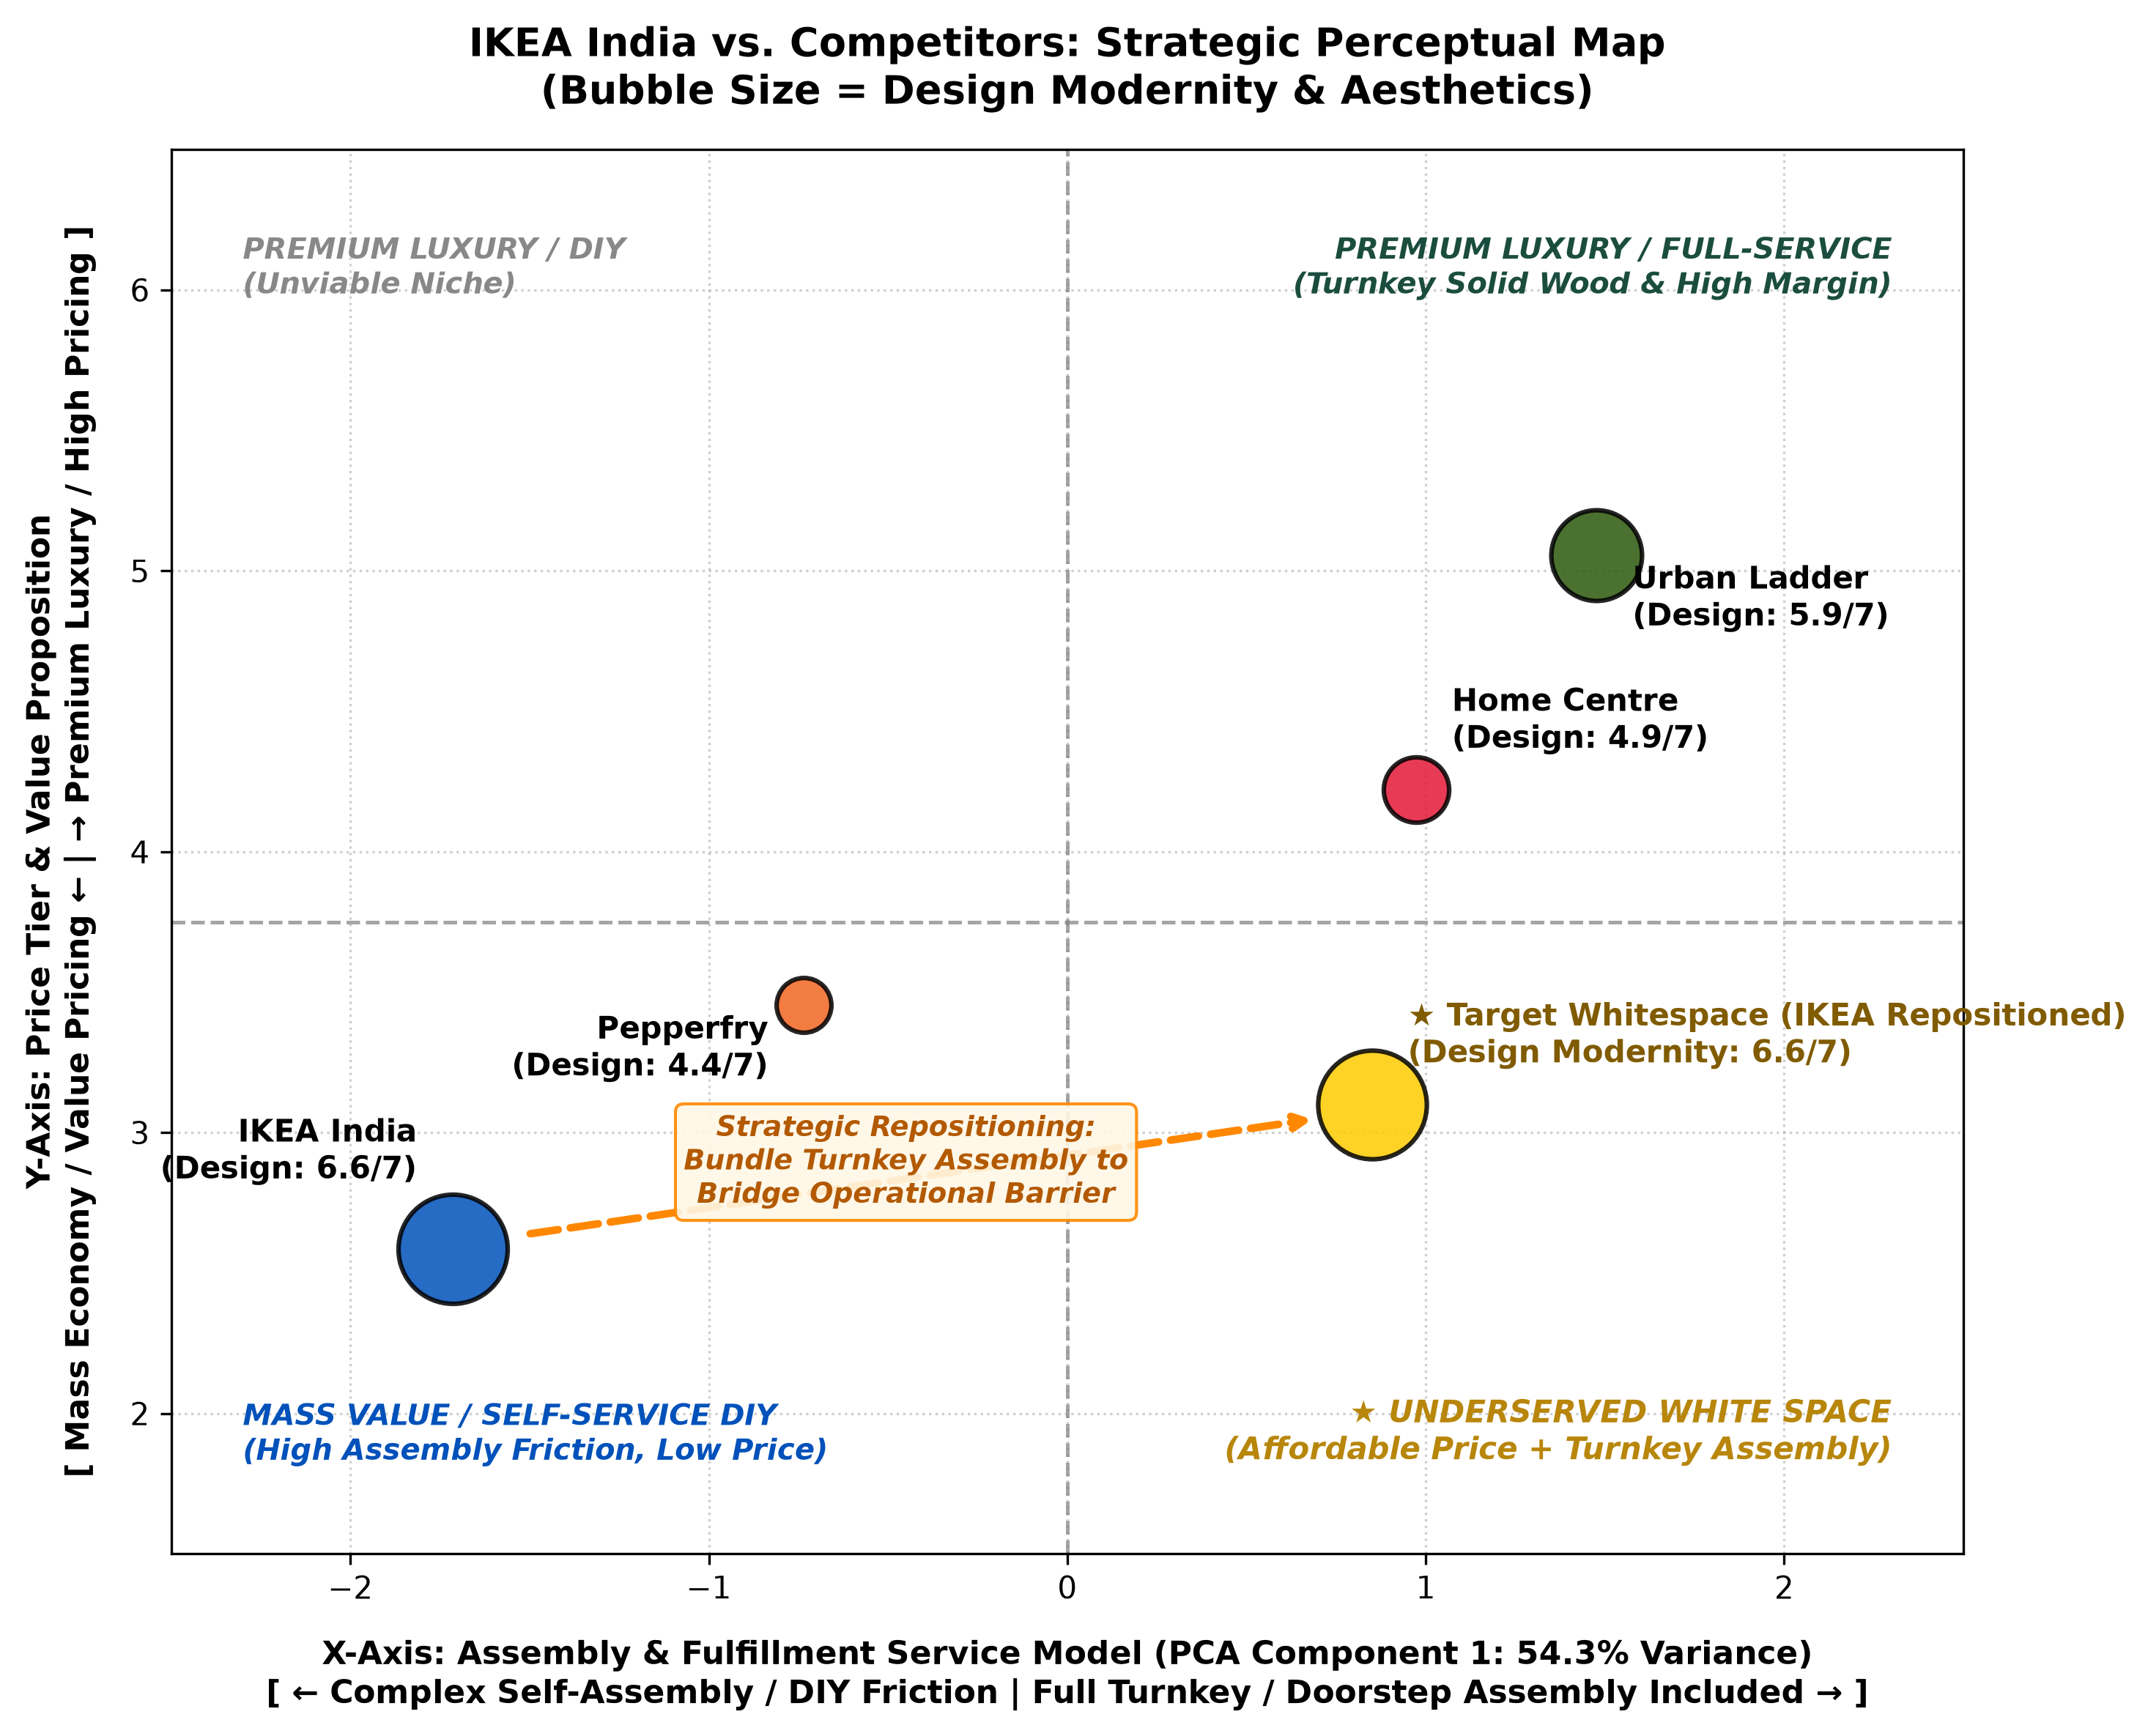

Saved map image: strategic_perceptual_map_optionA.png


In [ ]:
"""
IKEA India - Strategic Perceptual Mapping (Option A: Construct-Level PCA)
Input:  Raw_IKEA_india_perceptual_survey.xlsx
Output: perceptual_mapping_coordinates.xlsx & strategic_perceptual_map_optionA.png
Prerequisites: pip install pandas openpyxl scikit-learn matplotlib
"""

import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ==============================================================================
# 1. INGEST SURVEY DATASET
# ==============================================================================
print(">>> [1/4] Loading customer perceptual survey...")
df_survey = pd.read_excel("Raw_IKEA_india_perceptual_survey.xlsx")

# Operational service cluster for PCA
service_cols = [
    "DIY_Assembly_Ease",
    "Customer_Service",
    "Delivery_Speed",
    "Material_Durability",
]

# ==============================================================================
# 2. CONSTRUCT-LEVEL PCA (OPERATIONAL SERVICE MODEL)
# ==============================================================================
print(">>> [2/4] Fitting PCA on Operational Service Battery...")
scaler_service = StandardScaler()
X_serv_scaled = scaler_service.fit_transform(df_survey[service_cols])

pca_service = PCA(n_components=1)
serv_comp = pca_service.fit_transform(X_serv_scaled)[:, 0]

# Ensure orientation: Positive = Turnkey Assembly / High Service
if pca_service.components_[0][0] < 0:
  serv_comp = -serv_comp

df_survey["PCA_Assembly_Service_Score"] = serv_comp
var_explained = pca_service.explained_variance_ratio_[0] * 100

# Convert Price Accessibility to Price Tier (1 = Economy, 7 = Luxury)
df_survey["Price_Premium_Tier"] = 8 - df_survey["Price_Accessibility"]

# Compute Brand Centroids
brand_centroids = (
    df_survey.groupby("Brand")
    .agg({
        "PCA_Assembly_Service_Score": "mean",
        "Price_Premium_Tier": "mean",
        "Design_Modernity": "mean",
    })
    .reset_index()
)

# Define Target Whitespace Benchmark
whitespace_point = pd.DataFrame([{
    "Brand": "★ Target Whitespace (IKEA Repositioned)",
    "PCA_Assembly_Service_Score": 0.85,
    "Price_Premium_Tier": 3.10,
    "Design_Modernity": 6.60,
}])
brand_centroids = pd.concat(
    [brand_centroids, whitespace_point], ignore_index=True
)

# ==============================================================================
# 3. EXPORT CLEAN DATA TO EXCEL FOR TABLEAU
# ==============================================================================
print(">>> [3/4] Exporting updated coordinates to Excel...")
output_pca_file = "perceptual_mapping_coordinates.xlsx"

brand_centroids_export = brand_centroids.rename(
    columns={
        "PCA_Assembly_Service_Score": "X_Axis_Assembly_Service_Model",
        "Price_Premium_Tier": "Y_Axis_Price_Tier",
        "Design_Modernity": "Bubble_Size_Design_Modernity",
    }
).round(3)

pca_service_loadings = pd.DataFrame({
    "Operational_Attribute": service_cols,
    "PCA_Loading": (
        -pca_service.components_[0]
        if pca_service.components_[0][0] < 0
        else pca_service.components_[0]
    ).round(3),
    "Variance_Explained_Pct": round(var_explained, 1),
})

respondent_export = df_survey[[
    "Respondent_ID",
    "Metro_City",
    "Brand",
    "PCA_Assembly_Service_Score",
    "Price_Premium_Tier",
    "Design_Modernity",
    "DIY_Assembly_Ease",
    "Customer_Service",
    "Delivery_Speed",
    "Material_Durability",
    "Price_Accessibility",
]].rename(
    columns={
        "PCA_Assembly_Service_Score": "X_Axis_Assembly_Service_Score",
        "Price_Premium_Tier": "Y_Axis_Price_Tier",
        "Design_Modernity": "Bubble_Size_Design_Modernity",
    }
).round(3)

with pd.ExcelWriter(output_pca_file, engine="openpyxl") as writer:
  brand_centroids_export.to_excel(
      writer, sheet_name="Brand_Centroids", index=False
  )
  pca_service_loadings.to_excel(
      writer, sheet_name="PCA_Service_Loadings", index=False
  )
  respondent_export.to_excel(
      writer, sheet_name="All_Respondent_Scores", index=False
  )

print(f"Saved Excel deliverable: {output_pca_file}")

# ==============================================================================
# 4. RENDER VISUALIZATION
# ==============================================================================
print(">>> [4/4] Rendering publication-quality strategic map...")
plt.figure(figsize=(10, 8), dpi=300)
plt.xlim(-2.5, 2.5)
plt.ylim(1.5, 6.5)

y_mid = 3.75
plt.axvline(0, color="#7f7f7f", linestyle="--", linewidth=1.2, alpha=0.7)
plt.axhline(y_mid, color="#7f7f7f", linestyle="--", linewidth=1.2, alpha=0.7)

plt.text(
    -2.3,
    6.2,
    "PREMIUM LUXURY / DIY\n(Unviable Niche)",
    fontsize=9.5,
    color="#888888",
    weight="bold",
    style="italic",
    va="top",
    ha="left",
)
plt.text(
    2.3,
    6.2,
    "PREMIUM LUXURY / FULL-SERVICE\n(Turnkey Solid Wood & High Margin)",
    fontsize=9.5,
    color="#1b4d3e",
    weight="bold",
    style="italic",
    va="top",
    ha="right",
)
plt.text(
    -2.3,
    1.8,
    "MASS VALUE / SELF-SERVICE DIY\n(High Assembly Friction, Low Price)",
    fontsize=9.5,
    color="#0051ba",
    weight="bold",
    style="italic",
    va="bottom",
    ha="left",
)
plt.text(
    2.3,
    1.8,
    "★ UNDERSERVED WHITE SPACE\n(Affordable Price + Turnkey Assembly)",
    fontsize=10,
    color="#b8860b",
    weight="bold",
    style="italic",
    va="bottom",
    ha="right",
)

colors = {
    "IKEA India": "#0051ba",
    "Home Centre": "#e31837",
    "Pepperfry": "#f26522",
    "Urban Ladder": "#2b580c",
    "★ Target Whitespace (IKEA Repositioned)": "#ffcc00",
}

for _, row in brand_centroids.iterrows():
  b_name = row["Brand"]
  x = row["PCA_Assembly_Service_Score"]
  y = row["Price_Premium_Tier"]
  design = row["Design_Modernity"]
  c = colors.get(b_name, "black")
  bubble_size = (design**3.3) * 2.5
  plt.scatter(
      x,
      y,
      color=c,
      s=bubble_size,
      edgecolors="black",
      linewidth=1.5,
      alpha=0.85,
      zorder=5,
  )

  if "Target" in b_name:
    plt.text(
        x + 0.1,
        y + 0.15,
        f"{b_name}\n(Design Modernity: {design:.1f}/7)",
        fontsize=10,
        weight="bold",
        color="#805b00",
        zorder=6,
    )
  elif "IKEA" in b_name:
    plt.text(
        x - 0.1,
        y + 0.25,
        f"{b_name}\n(Design: {design:.1f}/7)",
        fontsize=10,
        weight="bold",
        ha="right",
        zorder=6,
    )
  elif "Urban" in b_name:
    plt.text(
        x + 0.1,
        y - 0.25,
        f"{b_name}\n(Design: {design:.1f}/7)",
        fontsize=10,
        weight="bold",
        zorder=6,
    )
  elif "Home" in b_name:
    plt.text(
        x + 0.1,
        y + 0.15,
        f"{b_name}\n(Design: {design:.1f}/7)",
        fontsize=10,
        weight="bold",
        zorder=6,
    )
  else:
    plt.text(
        x - 0.1,
        y - 0.25,
        f"{b_name}\n(Design: {design:.1f}/7)",
        fontsize=10,
        weight="bold",
        ha="right",
        zorder=6,
    )

# Migration vector
ikea_pt = brand_centroids[brand_centroids["Brand"] == "IKEA India"].iloc[0]
white_pt = brand_centroids[
    brand_centroids["Brand"] == "★ Target Whitespace (IKEA Repositioned)"
].iloc[0]
plt.annotate(
    "",
    xy=(
        white_pt["PCA_Assembly_Service_Score"] - 0.15,
        white_pt["Price_Premium_Tier"] - 0.05,
    ),
    xytext=(
        ikea_pt["PCA_Assembly_Service_Score"] + 0.2,
        ikea_pt["Price_Premium_Tier"] + 0.05,
    ),
    arrowprops=dict(arrowstyle="->", color="#ff8800", lw=2.5, ls="--"),
)
plt.text(
    -0.45,
    2.75,
    "Strategic Repositioning:\nBundle Turnkey Assembly to\nBridge Operational"
    " Barrier",
    fontsize=9,
    weight="bold",
    color="#b35900",
    ha="center",
    style="italic",
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="#fff8e7",
        edgecolor="#ff8800",
        alpha=0.9,
    ),
)

plt.title(
    "IKEA India vs. Competitors: Strategic Perceptual Map\n(Bubble Size = Design"
    " Modernity & Aesthetics)",
    fontsize=13,
    weight="bold",
    pad=15,
)
plt.xlabel(
    f"X-Axis: Assembly & Fulfillment Service Model (PCA Component 1:"
    f" {var_explained:.1f}% Variance)\n[ ← Complex Self-Assembly / DIY"
    " Friction | Full Turnkey / Doorstep Assembly Included → ]",
    fontsize=10.5,
    weight="bold",
    labelpad=10,
)
plt.ylabel(
    "Y-Axis: Price Tier & Value Proposition\n[ Mass Economy / Value Pricing ← |"
    " → Premium Luxury / High Pricing ]",
    fontsize=10.5,
    weight="bold",
    labelpad=10,
)

plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()
plt.savefig("strategic_perceptual_map_optionA.png", dpi=300)
plt.close()
print("Saved map image: strategic_perceptual_map_optionA.png")